# TP4 — RNN, LSTM, Transformer, mini-GPT et mini-BERT

**Livrable.** Ce notebook répond à la première partie et aux trois exercices de `architecture_transformer.ipynb`.
Les exemples GPT et BERT de la première partie sont réalisés et testés dans les exercices 2 et 3,
avec des modèles Transformer entraînés localement, sans téléchargement de poids pré-entraînés.
Exécuter les cellules dans l'ordre depuis le dossier `TP4`. Les résultats dépendent de la graine et du CPU.


In [1]:
from __future__ import annotations

import copy
import math
import random
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT = Path.cwd()
print("PyTorch:", torch.__version__, "| appareil:", DEVICE)


PyTorch: 2.12.0+cpu | appareil: cpu


## Partie 1 — Prévision de la sinusoïde

Chaque entrée contient 10 valeurs consécutives de $\sin(x)$ ; la cible est la valeur immédiatement suivante.
Le découpage est chronologique pour simuler une prévision sur les observations futures.


In [2]:
x_axis = torch.linspace(0, 20, 200)
series = torch.sin(x_axis)
WINDOW = 10
features = torch.stack([series[i:i + WINDOW] for i in range(len(series) - WINDOW)]).unsqueeze(-1)
targets = series[WINDOW:].unsqueeze(-1)
X_train, X_test = features[:150].to(DEVICE), features[150:].to(DEVICE)
y_train, y_test = targets[:150].to(DEVICE), targets[150:].to(DEVICE)
assert X_train.shape == (150, 10, 1) and y_test.shape == (40, 1)
print("Train:", tuple(X_train.shape), "| Test:", tuple(X_test.shape))


Train: (150, 10, 1) | Test: (40, 10, 1)


In [3]:
class SineRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.recurrent = nn.RNN(1, 16, batch_first=True)
        self.head = nn.Linear(16, 1)

    def forward(self, x):
        states, _ = self.recurrent(x)
        return self.head(states[:, -1])


class SineLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.recurrent = nn.LSTM(1, 16, batch_first=True)
        self.head = nn.Linear(16, 1)

    def forward(self, x):
        states, _ = self.recurrent(x)
        return self.head(states[:, -1])


class SineTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(1, 16)
        self.position = nn.Embedding(WINDOW, 16)
        layer = nn.TransformerEncoderLayer(16, 2, 32, dropout=0.0, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=1)
        self.head = nn.Linear(16, 1)

    def forward(self, x):
        positions = torch.arange(x.size(1), device=x.device)
        states = self.encoder(self.projection(x) + self.position(positions))
        return self.head(states[:, -1])


def train_sine(model, epochs=250):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    criterion = nn.MSELoss()
    history = []
    for epoch in range(epochs):
        model.train()
        loss = criterion(model(X_train), y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        history.append(loss.item())
    model.eval()
    with torch.no_grad():
        pred = model(X_test).cpu().numpy().ravel()
    return model, history, pred


sine_results = {}
for name, model in [("RNN", SineRNN()), ("LSTM", SineLSTM()), ("Transformer", SineTransformer())]:
    fitted, history, pred = train_sine(model)
    mse = float(np.mean((pred - y_test.cpu().numpy().ravel()) ** 2))
    sine_results[name] = {"model": fitted, "history": history, "pred": pred, "mse": mse}
    print(f"{name:12s} | MSE test: {mse:.6f} | premier réel/prédit: {y_test[0].item():.3f}/{pred[0]:.3f}")


RNN          | MSE test: 0.000050 | premier réel/prédit: -0.364/-0.361


LSTM         | MSE test: 0.000012 | premier réel/prédit: -0.364/-0.362


Transformer  | MSE test: 0.000083 | premier réel/prédit: -0.364/-0.372


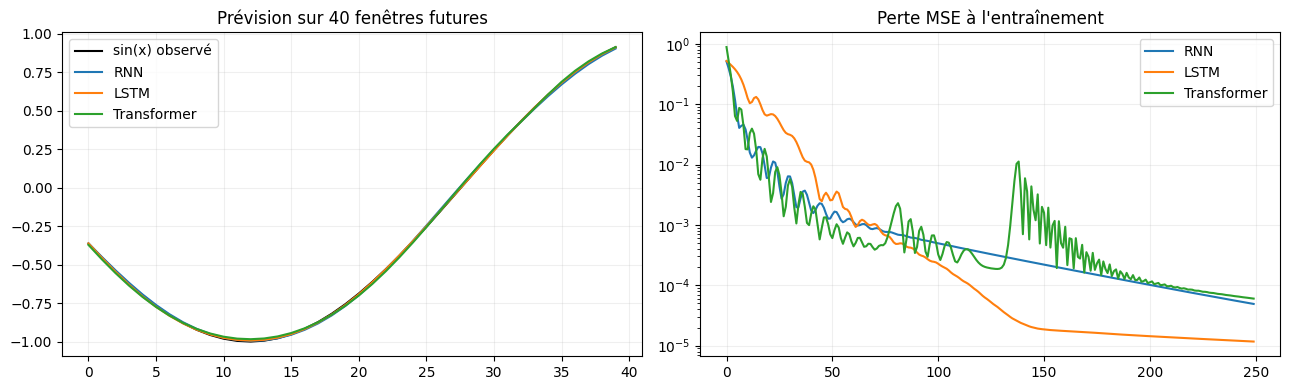

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(y_test.cpu().numpy().ravel(), label="sin(x) observé", color="black")
for name, result in sine_results.items():
    axes[0].plot(result["pred"], label=name)
    axes[1].plot(result["history"], label=name)
axes[0].set_title("Prévision sur 40 fenêtres futures")
axes[1].set_title("Perte MSE à l'entraînement")
axes[1].set_yscale("log")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
